# **Exercício 5 \- cap 12**

 **Discente:** Raphael Ramos da Silva

Para o exercício de deconvolução com RNNs disponibilizado no [**link**](http://utam.gg.utah.edu/Classes/ML/LAB1/Chapter.CNN.RNN/RNN_lab.html):

- Executar as atividades (1), (2) e (3) descritas na seção 6. Questions.
- Entregar os códigos em Matlab com uma análise dos resultados ou um notebook em Python contendo os códigos e as análises.

**1. Use the reflectivity as the input data and the seismogram as the output, which means using RNN to mimic convolution. How does the result look like? Why is that?**

**Arquitetura da RNN (`RNN_deconv.m`)**

A rede é criada com `layrecnet(1,[10],'trainlm')`, uma *Layer-Recurrent Network* (generalização da rede de Elman):

| Camada | Neurônios | Ativação | Entradas |
|---|:---:|:---:|---|
| Entrada | 1 | – | amostra do sinal no instante *t* |
| Oculta | 10 | `tansig` | entrada $x(t)$ (atraso 0) + realimentação da própria saída $h(t-1)$ (atraso 1) |
| Saída | 1 | `purelin` | $h(t)$ |

$$h(t) = \tanh\left(W_{in}\,x(t) + W_{rec}\,h(t-1) + b_1\right), \qquad y(t) = W_{out}\,h(t) + b_2$$

A realimentação $h(t-1)$ é a memória da rede: o estado oculto resume todo o histórico de entradas, permitindo que a saída dependa das amostras passadas, como acontece em uma convolução. A rede tem 131 pesos (10 de entrada, 100 recorrentes, 10 de saída e 11 bias) e é treinada por Levenberg-Marquardt (`trainlm`) por até 500 épocas.

Os dados de treino são 2000 amostras com 100 refletividades aleatórias em $[-1, 1]$ (uma a cada 20 amostras), convolvidas com uma wavelet Ricker de 1 Hz. O teste usa uma sequência de 200 amostras com 9 refletividades fixas.

**Resultados**

In [5]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg


def visualizar(figuras, largura=7, altura=6):
    """Exibe as imagens lado a lado, uma por coluna, com o título acima de cada uma."""
    fig, axes = plt.subplots(1, len(figuras), figsize=(largura * len(figuras), altura), squeeze=False)
    for ax, (titulo, caminho) in zip(axes[0], figuras):
        ax.imshow(mpimg.imread(caminho))
        ax.set_title(titulo, fontweight="bold")
        ax.axis("off")
    fig.tight_layout()
    plt.show()

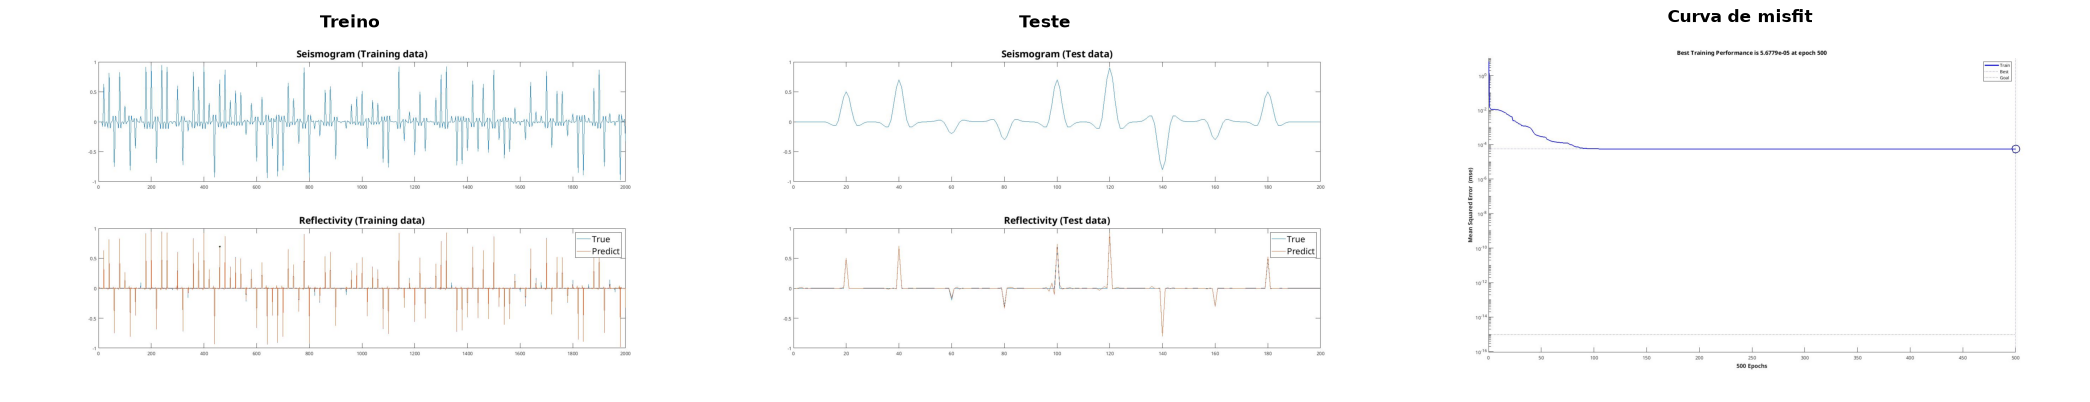

In [6]:
visualizar([
    ("Treino", "imagens/RNN_deconv_1_training.jpg"),
    ("Teste", "imagens/RNN_deconv_1_test.jpg"),
    ("Curva de misfit", "imagens/RNN_deconv_1_misfit.jpg"),
])

- O MSE cai rapidamente até ~100 épocas e estabiliza em **5,68e-5** (época 500), longe do objetivo de 1e-15.
- No treino, as refletividades previstas coincidem visualmente com as verdadeiras.
- No teste, posições e sinais de todos os picos são recuperados, mas aparecem pequenos erros: amplitude subestimada em *t* = 60 e oscilações espúrias perto de *t* = 100, onde a wavelet de um evento se sobrepõe à do vizinho.

**Por quê?** A relação entre sismograma e refletividade é um filtro linear de curta duração (o comprimento da wavelet). Uma RNN com estado recorrente consegue aproximar esse filtro, pois $h(t)$ guarda as amostras recentes necessárias. O platô do misfit indica que 10 neurônios com um único atraso têm capacidade limitada para representar o filtro exatamente, o que explica os resíduos onde há interferência entre wavelets.

**2. Modify the structure and the parameters of RNN. See how the RNN parameter will change the result.**

Em `RNN_deconv2.m` foi adicionada uma segunda camada oculta: `layrecnet(1,[10 10],'trainlm')`. Cada camada oculta tem sua própria realimentação de atraso 1, e o número de pesos sobe de 131 para 341. Os demais parâmetros foram mantidos.

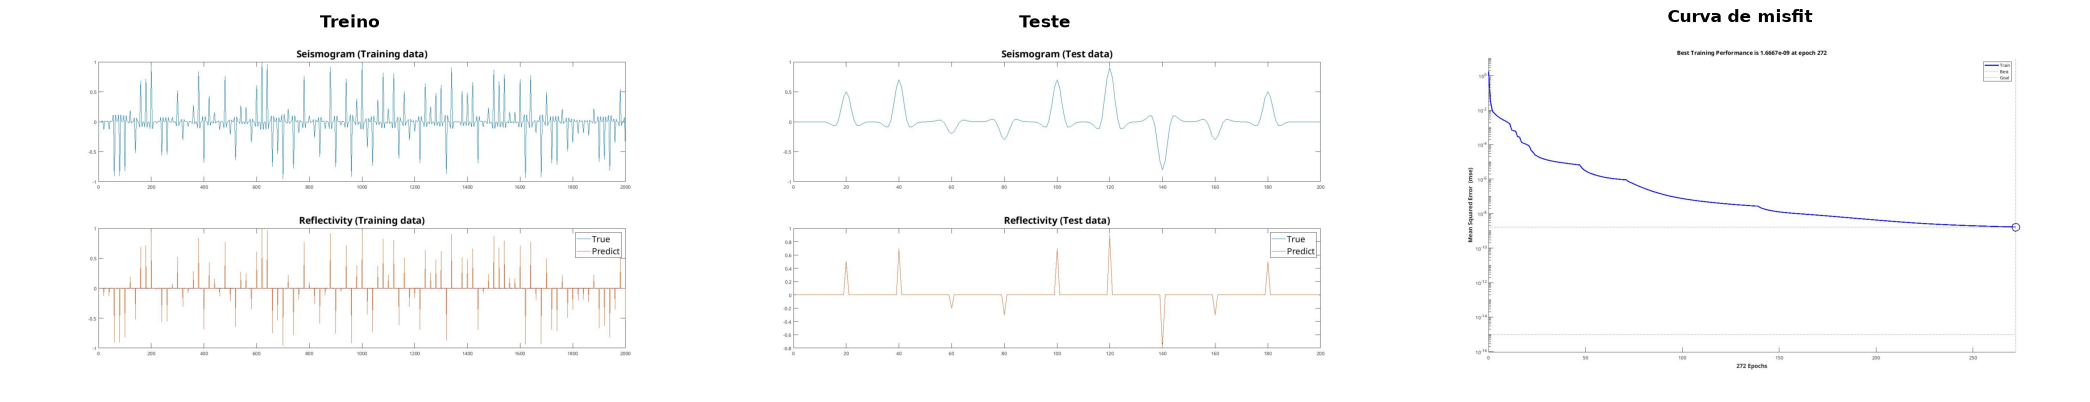

In [7]:
visualizar([
    ("Treino", "imagens/RNN_deconv_2_training.jpg"),
    ("Teste", "imagens/RNN_deconv_2_test.jpg"),
    ("Curva de misfit", "imagens/RNN_deconv_2_misfit.jpg"),
])

| | 1 camada `[10]` | 2 camadas `[10 10]` |
|---|:---:|:---:|
| Pesos | 131 | 341 |
| Melhor MSE de treino | 5,68e-5 | **1,67e-9** |
| Época final | 500 (limite) | 272 (parada antecipada) |
| Teste | erros de amplitude e oscilações espúrias | picos quase perfeitos, apenas leve subestimação em *t* = 140 |

A segunda camada aumenta a capacidade e a memória da rede: o MSE de treino cai cerca de 4 ordens de grandeza e continua diminuindo, em vez de estabilizar, e o treino termina antes das 500 épocas por um critério de parada do `trainlm`. No teste, as oscilações espúrias desaparecem e as amplitudes ficam praticamente iguais às verdadeiras, ou seja, não houve overfitting. O custo é um treino mais lento, pois o Levenberg-Marquardt cresce com o quadrado do número de pesos.

Como os dados de treino são gerados com `rand` sem semente fixa, cada execução usa refletividades e pesos iniciais diferentes. Parte da diferença entre os dois casos pode vir disso.

**3. This lab uses the conventional RNN without gate. If you are interested in LSTM, a binary calculator trained by LSTM is in `./RNN_binary_lstm.m`.**

O script treina uma LSTM para somar dois números binários de 8 bits. A cada passo de tempo, a rede recebe um bit de cada parcela (do menos para o mais significativo) e prevê o bit da soma. O "vai um" precisa ser lembrado de um passo para o próximo, por isso o problema exige memória.

| Componente | Configuração |
|---|---|
| Entrada | 2 (um bit de *a* e um de *b*) |
| Estado oculto | 32 |
| Saída | 1 (`sigmoid`) |
| Portas | entrada, esquecimento, saída (`sigmoid`) e candidata *g* (`tanh`) |
| Treino | 9000 iterações, taxa de aprendizado 0,1 |

$$C(t) = C(t-1)\odot f(t) + g(t)\odot i(t), \qquad h(t) = \tanh(C(t))\odot o(t)$$

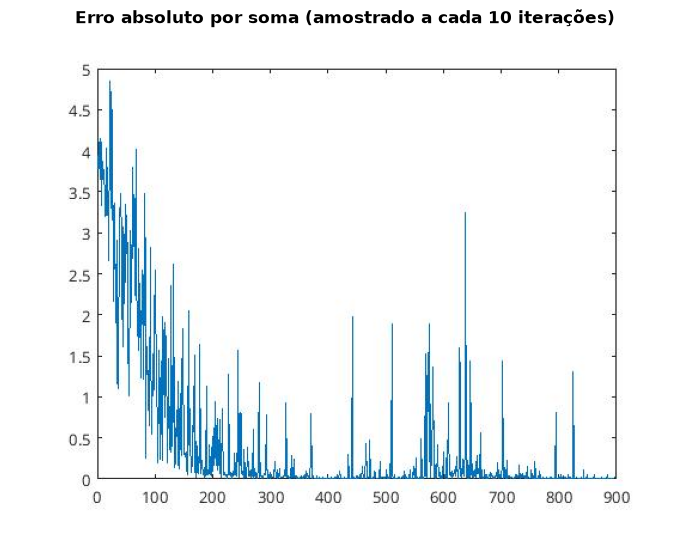

In [8]:
visualizar([
    ("Erro absoluto por soma (amostrado a cada 10 iterações)", "imagens/RNN_binary_lstm.jpg"),
])

O erro começa em ~4 (equivalente a ~0,5 por bit, ou seja, chute aleatório) e cai para perto de zero após ~2500 iterações, quando a rede passa a somar corretamente. Os picos esporádicos posteriores correspondem a somas com longas cadeias de "vai um", que são mais difíceis.

Diferente da RNN convencional, a LSTM tem uma célula de memória $C(t)$ controlada por portas. A porta de esquecimento decide o que manter, e a de entrada decide o que escrever. Isso permite preservar informação por muitos passos e reduz o problema de gradientes que desaparecem ou explodem na retropropagação no tempo.